# Week 10 (Wed) - Random Numbers in Python & Monte Carlo - HW 9

## 1) Random Numbers and Radio Activity

The isotope $^{213}$Bi decays to stable $^{209}$Bi via one of two different routes, with probabilities and
half-lives thus

<img src="Decay9.jpg" alt="Decay process for Bi213 to Bi209" title="Bismuth Decay" />

*(Technically, $^{209}$Bi isnt really stable, but it has a half-life of more than $10^{19}$ years, a billion
times the age of the universe, so it might as well be.)*

Starting with a sample consisting of 10,000 atoms of $^{213}$Bi, simulate the decay of the atoms
by dividing time into slices of length $\delta t = 1$s each and on each step doing
the following:

1. For each atom of $^{209}$Pb in turn, decide at random, with the appropriate probability, whether it decays or not. (The probability can be calculated from $p(t) = 1 − 2t/\tau $, where $\tau$ is the half life.) Count the total number that decay, subtract it from the number of $^{209}$Pb atoms, and add it to the number of $^{209}$Bi atoms.

2. Now do the same for $^{209}$Tl, except that decaying atoms are subtracted from the total for $^{209}$Tl and added to the total for $^{209}$Pb.

3. For $^{213}$Bi the situation is more complicated: when a $^{213}$Bi atom decays you have to decide at random with the appropriate probability the route by which it decays. Count the numbers that decay by each route and add and subtract accordingly.

**Note that you have to work up the chain from the bottom like this, not down from the top,
to avoid inadvertently making the same atom decay twice on a single step.**

Keep track of the number of atoms of each of the four isotopes at all times for 20,000 seconds
and make a **single** graph showing the four counts of atoms as a function of time on the same axes.



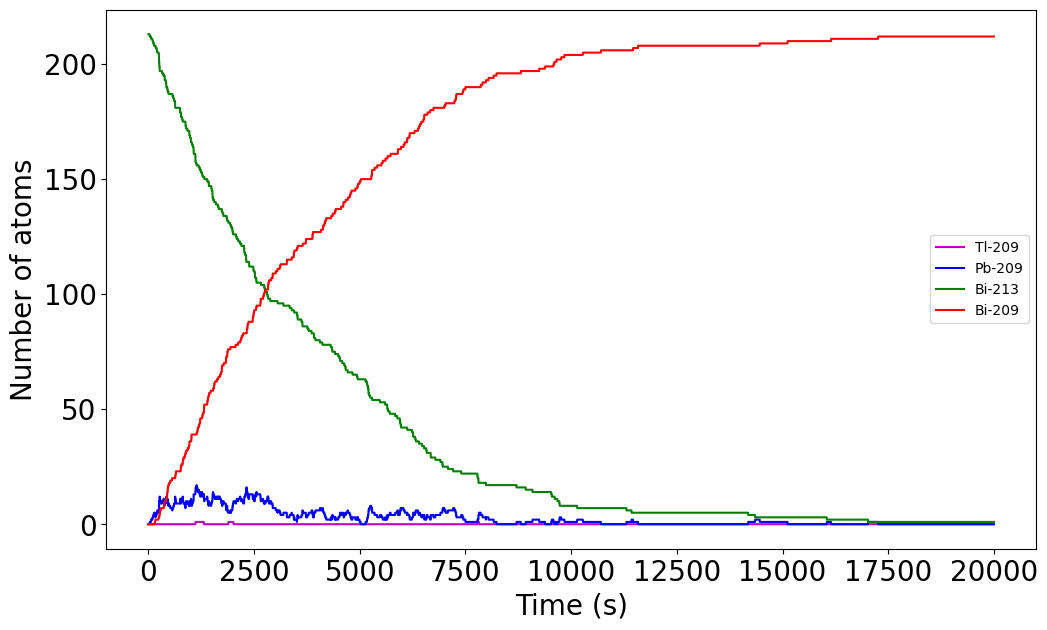

In [8]:
import numpy as np
from numpy import arange
import matplotlib.pyplot as plt

# Constants
Bi = 213               # Initial number of Bismuth-213 atoms
NPb = 0                # Initial number of Lead-209 atoms
NTl = 0                # Initial number of Thallium-209 atoms
Nbiz = 0               # Initial number of Bismuth-209 atoms
h = 1.0                # Time step (seconds)
tmax = 20000           # Total time (seconds)

# Half-lives (seconds)
T_Bi = 46 * 60         # Half-life of Bi-213 (46 min)
T_Pb = 3.3 * 60        # Half-life of Pb-209 (3.3 min)
T_Tl = 2.2 * 60        # Half-life of Tl-209 (2.2 min)

# Probability of decay in one time step
p_Bi = 1 - 2**(-h/T_Bi)
p_decay_Pb = 1 - 2**(-h/T_Pb)
p_decay_Tl = 1 - 2**(-h/T_Tl)

# Branching probabilities for Bi-213
p_Tl = 0.0209          # 2.09% chance of decay into Tl-209
p_Pb = 0.9791          # 97.91% chance of decay into Pb-209

# Lists of plot points
tpoints = arange(0.0, tmax, h)

Bipoints = []          # Number of Bi-213 atoms at each time step
Pbpoints = []          # Number of Pb-209 atoms at each time step
Tlpoints = []          # Number of Tl-209 atoms at each time step
Bizpoints = []         # Number of Bi-209 atoms at each time step

# Main loop
for t in tpoints:      # For time 0-1000 seconds

    Bipoints.append(Bi)    # Append starting number of Bi-213 atoms
    Tlpoints.append(NTl)   # Append starting number of Tl-209 atoms
    Pbpoints.append(NPb)   # Append starting number of Pb-209 atoms
    Bizpoints.append(Nbiz) # Append starting number of Bi-209 atoms

    # Calculate the number of atoms that decay
    decay_Bi_Pb = 0        # Bi-213 decaying into Pb-209
    decay_Bi_Tl = 0        # Bi-213 decaying into Tl-209
    decay_Tl_Pb = 0        # Tl-209 decaying into Pb-209
    decay_Pb_Bi209 = 0     # Pb-209 decaying into Bi-209

    # Determine number of Bi-213 atoms that decay
    for i in range(Bi):
        if np.random.random() < p_Bi:
            random = np.random.random()
            if random < p_Pb:
                decay_Bi_Pb += 1
            else:
                decay_Bi_Tl += 1

    # Determine number of Tl-209 atoms that decay
    for i in range(NTl):
        if np.random.random() < p_decay_Tl:
            decay_Tl_Pb += 1
    # Determine number of Pb-209 atoms that decay
    for i in range(NPb):
        if np.random.random() < p_decay_Pb:
            decay_Pb_Bi209 += 1
    # Update number of atoms after decay
    Bi -= (decay_Bi_Pb + decay_Bi_Tl)
    NTl += decay_Bi_Tl - decay_Tl_Pb
    NPb += decay_Bi_Pb + decay_Tl_Pb - decay_Pb_Bi209
    Nbiz += decay_Pb_Bi209


# Make the graph
fig = plt.figure(figsize=(12,7))
ax = fig.add_subplot(111)
ax.plot(tpoints, Tlpoints, c='m', label='Tl-209')  # Plot Tl vs. time
ax.plot(tpoints, Pbpoints, c='b', label='Pb-209')  # Plot Pb vs. time
ax.plot(tpoints, Bipoints, c='g', label='Bi-213')  # Plot Bi vs. time
ax.plot(tpoints, Bizpoints, c='r', label='Bi-209') # Plot Bi-209 vs. time
# Add the labels
ax.set_xlabel("Time (s)", size=20)
ax.set_ylabel("Number of atoms", size=20)
# Increase the size of the numbers on the axes
ax.xaxis.set_tick_params(labelsize=20)
ax.yaxis.set_tick_params(labelsize=20)
ax.legend()
plt.show()

## 2) Lets Make a Deal
Monte Carlo methods are often useful to ensure that our thinking is reasonable. A good
example of this kind of use is to investigate a simple problem that generated much attention
several years ago and for which many mathematicians obtained an incorrect solution.

The problem was the analysis of the optimal strategy in a television game show popular at
the time. The show was Lets Make a Deal with host Monty Hall. At some point in the show,
a contestant was given a choice of selecting one of three possible items, each concealed behind
one of three closed doors. The items varied considerably in value.

After the contestant made a choice but before the chosen door was opened, the
host, who knew where the most valuable item was, would open one of the doors
not selected and reveal a worthless item.

**The host would then offer to let the contestant select a different door from what was originally
selected. The question, of course, is should the contestant switch?**

<img src="Monty_Hall_Problem.jpg" alt="Decay process for Bi213 to Bi209" title="Bismuth Decay" />



Much interest in this problem was generated when it was analyzed by a popular magazine
writer, Marilyn vos Savant, who concluded that the optimal strategy is to switch. This
strategy is counterintuitive to many mathematicians, who would say that there is nothing to
be gained by switching; that is, that the probability of improving the selection is 0.5. Study
this problem by Monte Carlo methods. Be careful to understand all of the assumptions

**Write a code that implement this test for 1000 “games”, 500 where the contestant choose to KEEP their choice of door, and 500 where contestant chooses to CHANGE their choice of door:**


## Determine if there is probability of improving the selection by switching, and if so by how much?

Think about what you NEED to keep track of BEFORE you start coding!!   Use Logic to break down the problem first!!


In [ ]:
# Write Code Here

In [21]:
from numpy import random

win_keep = 0
lose_keep = 0

for i in range(0, 500):
    deal = ["goat", "goat", "car"]
    random.shuffle(deal)
    choice = random.choice(deal)
    if choice == "car":
        win_keep += 1
    else:
        lose_keep += 1

win_switch = 0
lose_switch = 0

for i in range(0, 500):
    deal = ["goat", "goat", "car"]
    random.shuffle(deal)
    # Choose an initial door
    choice_index = random.choice(3)
    # Host reveals a goat behind a different door
    goat_doors = [
        j for j in range(3)
        if j != choice_index and deal[j] == "goat"
    ]
    revealed_index = random.choice(goat_doors)

    # Switch to the remaining unopened door
    switch_index = [
        j for j in range(3)
        if j != choice_index and j != revealed_index
    ][0]

    if deal[switch_index] == "car":
        win_switch += 1
    else:
        lose_switch += 1

print("Winning by keeping:", win_keep)
print("Losing by keeping:", lose_keep)
print("Winning by switch", win_switch) 
print("Losing by switching", lose_switch)


Winning by keeping: 169
Losing by keeping: 331
Winning by switch 338
Losing by switching 162


In [19]:
print (win_keep/lose_keep, "vs", win_switch/lose_switch)

0.5151515151515151 vs 2.0120481927710845


This shows that we win more with switching